# Final project: Intelligent Medical Image Classification
Alexa Rodríguez Méndez 2133921 - Thursday N4

José Omar de Anda Garza 2012643 - Tuesday N4

## 1. Load libraries

In [21]:
import os
import json
import random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 2. Configuración
Hiperparámetros principales. `MODEL_TYPE = "transfer"` usa InceptionV3 preentrenada en ImageNet (etapa 1: entrenar solo la cabeza; etapa 2: ajuste fino de las últimas capas). `"custom"` usa la CNN propia.

In [22]:
SEED = 42
IMG_SIZE = (224, 224)       # tamaño uniforme de entrada
BATCH_SIZE = 32
MODEL_TYPE = "transfer"     # "transfer" (InceptionV3) o "custom" (CNN propia)
EPOCHS = 12                 # etapa 1
FINE_TUNE = True            # etapa 2 (solo transfer): ajuste fino
FINE_TUNE_EPOCHS = 10
FINE_TUNE_LAYERS = 40       # cuántas capas finales de InceptionV3 se descongelan
USE_AUGMENTATION = True     # flips, rotaciones y zoom ligeros
USE_COLOR_AUG = True        # variaciones de color/escala de grises (robustez a otras cámaras)
TARGET_SPECIFICITY = 0.85   # especificidad mínima al elegir el umbral en validación

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

## 3. Load data
Se descarga el dataset de Kaggle (`mos3santos/breast-cancer-diagnosis`) con `kagglehub`. Si la descarga falla, descarga el .zip desde Kaggle, súbelo a Colab, descomprímelo y asigna la ruta a `dataset_path`.

In [23]:
!pip install -q kagglehub
import kagglehub

dataset_path = kagglehub.dataset_download("mos3santos/breast-cancer-diagnosis")
print("Dataset descargado en:", dataset_path)

Using Colab cache for faster access to the 'breast-cancer-diagnosis' dataset.
Dataset descargado en: /kaggle/input/breast-cancer-diagnosis


In [24]:
# Buscar la carpeta "Dados"; si no existe se usa la raíz descargada
DATA_DIR = dataset_path
for root, dirs, files in os.walk(dataset_path):
    if os.path.basename(root).lower() == "dados":
        DATA_DIR = root
        break
print("Carpeta de datos:", DATA_DIR, "\n")

# Estructura de carpetas (3 niveles) y tipos de archivo
for root, dirs, files in os.walk(DATA_DIR):
    depth = root[len(DATA_DIR):].count(os.sep)
    if depth <= 2:
        exts = Counter(os.path.splitext(f)[1].lower() for f in files)
        print("  " * depth + os.path.basename(root) + "/", dict(exts))

Carpeta de datos: /kaggle/input/breast-cancer-diagnosis/Dados 

Dados/ {'': 3, '.csv': 2, '.ods': 1}
  Imagens/ {}
    PACIENTE_0048/ {'.jpg': 27}
    PACIENTE_0107/ {'.jpg': 27}
    PACIENTE_0220/ {'.jpg': 27}
    PACIENTE_0273/ {'.jpg': 27}
    PACIENTE_0218/ {'.jpg': 27}
    PACIENTE_0190/ {'.jpg': 27}
    PACIENTE_0199/ {'.jpg': 27}
    PACIENTE_0244/ {'.jpg': 27}
    PACIENTE_0384/ {'.jpg': 27}
    PACIENTE_0170/ {'.jpg': 27}
    PACIENTE_0245/ {'.jpg': 27}
    PACIENTE_0090/ {'.jpg': 27}
    PACIENTE_0208/ {'.jpg': 27}
    PACIENTE_0130/ {'.jpg': 27}
    PACIENTE_0200/ {'.jpg': 27}
    PACIENTE_0061/ {'.jpg': 27}
    PACIENTE_0217/ {'.jpg': 27}
    PACIENTE_0016/ {'.jpg': 26}
    PACIENTE_0247/ {'.jpg': 1}
    PACIENTE_0115/ {'.jpg': 27}
    PACIENTE_0146/ {'.jpg': 27}
    PACIENTE_0125/ {'.jpg': 27}
    PACIENTE_0169/ {'.jpg': 27}
    PACIENTE_0080/ {'.jpg': 26}
    PACIENTE_0087/ {'.jpg': 27}
    PACIENTE_0328/ {'.jpg': 29}
    PACIENTE_0363/ {'.jpg': 30}
    PACIENTE_0398/ {'.

## 4. Data preprocessing
### 4.1 Etiquetas, lectura de imágenes y limpieza
Las imágenes están en `Dados/Imagens/PACIENTE_XXXX/` y el diagnóstico de cada paciente viene en `tabulares.csv` (columna `Diagnosis`). Se une la carpeta con el ID del paciente. Se excluyen los pacientes con diagnóstico `unknown`.
**Criterios de descarte de imágenes:** archivos corruptos o ilegibles, y lado menor a 32 px.

In [25]:
VALID_EXT = {".jpg", ".jpeg", ".png", ".bmp"}
MIN_SIDE = 32

# --- Diagnóstico por paciente ---
tab = pd.read_csv(os.path.join(DATA_DIR, "tabulares.csv"), sep=None, engine="python")
tab["Diagnosis"] = tab["Diagnosis"].astype(str).str.strip().str.lower()
print("Diagnósticos en tabulares.csv:")
print(tab["Diagnosis"].value_counts(), "\n")

NEGATIVE_DIAG = {"healthy"}           # sana
EXCLUDE_DIAG = {"unknown", "nan"}     # sin diagnóstico confirmado: se excluyen
tab = tab[~tab["Diagnosis"].isin(EXCLUDE_DIAG)].drop_duplicates("ID").copy()
tab["label"] = (~tab["Diagnosis"].isin(NEGATIVE_DIAG)).astype(int)   # 1 = patológica
print("Se consideran PATOLÓGICOS (1):", sorted(set(tab.loc[tab.label == 1, "Diagnosis"])))
print("Se consideran SANOS (0):", sorted(set(tab.loc[tab.label == 0, "Diagnosis"])), "\n")

NEGATIVE_CLASS, POSITIVE_CLASS = "healthy", "pathological"
patient_label = dict(zip(tab["ID"].astype(int), tab["label"]))

# --- Lectura de imágenes y limpieza ---
IMG_DIR = os.path.join(DATA_DIR, "Imagens")
rows, discarded = [], 0
for folder in sorted(os.listdir(IMG_DIR)):
    try:
        pid = int(folder.split("_")[-1])          # PACIENTE_0001 -> 1
    except ValueError:
        continue
    if pid not in patient_label:                   # paciente sin diagnóstico (unknown)
        continue
    fdir = os.path.join(IMG_DIR, folder)
    for f in sorted(os.listdir(fdir)):
        if os.path.splitext(f)[1].lower() not in VALID_EXT:
            continue
        path = os.path.join(fdir, f)
        try:
            with Image.open(path) as im:
                im.verify()                        # detecta archivos corruptos
            with Image.open(path) as im:
                w, h = im.size
            if min(w, h) < MIN_SIDE:
                raise ValueError("imagen demasiado pequeña")
            rows.append((pid, path, patient_label[pid]))
        except Exception:
            discarded += 1

df = pd.DataFrame(rows, columns=["pid", "path", "label"])
print("Imágenes válidas:", len(df), "| descartadas:", discarded)
print("Pacientes con imágenes:", df["pid"].nunique())
print("Imágenes por clase:", df["label"].map({0: NEGATIVE_CLASS, 1: POSITIVE_CLASS}).value_counts().to_dict())

Diagnósticos en tabulares.csv:
Diagnosis
healthy    178
sick       100
unknown      5
Name: count, dtype: int64 

Se consideran PATOLÓGICOS (1): ['sick']
Se consideran SANOS (0): ['healthy'] 

Imágenes válidas: 7245 | descartadas: 0
Pacientes con imágenes: 278
Imágenes por clase: {'healthy': 4510, 'pathological': 2735}


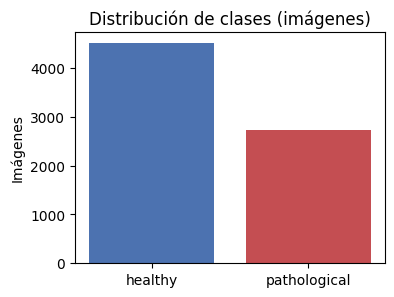

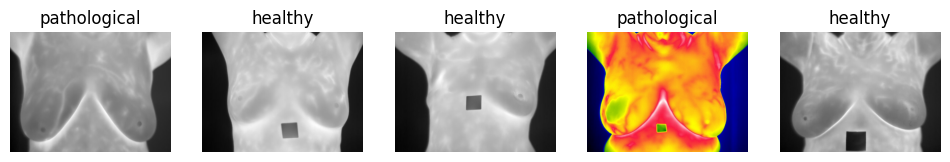

In [26]:
# Distribución de clases y ejemplos
counts = df["label"].map({0: NEGATIVE_CLASS, 1: POSITIVE_CLASS}).value_counts()
plt.figure(figsize=(4, 3))
plt.bar(counts.index, counts.values, color=["#4c72b0", "#c44e52"])
plt.title("Distribución de clases (imágenes)"); plt.ylabel("Imágenes")
plt.show()

plt.figure(figsize=(12, 3))
for i, idx in enumerate(random.sample(range(len(df)), 5)):
    plt.subplot(1, 5, i + 1)
    plt.imshow(Image.open(df.iloc[idx]["path"]).convert("RGB"))
    plt.title(NEGATIVE_CLASS if df.iloc[idx]["label"] == 0 else POSITIVE_CLASS)
    plt.axis("off")
plt.show()

### 4.2 División 80 % entrenamiento / 20 % prueba (por paciente)
Hay varias imágenes por paciente. Si se dividiera por imagen, fotos de la misma paciente caerían en entrenamiento y en prueba (*data leakage*) e inflarían el accuracy. Por eso la división 80/20 se hace **por paciente** (estratificada por diagnóstico). Del 80 % de entrenamiento se aparta un 15 % como validación.

In [27]:
patients = df.groupby("pid")["label"].first().reset_index()

train_p, test_p = train_test_split(patients, test_size=0.20, stratify=patients["label"], random_state=SEED)
train_p, val_p = train_test_split(train_p, test_size=0.15, stratify=train_p["label"], random_state=SEED)

def subset(pids):
    s = df[df["pid"].isin(pids)]
    return s["path"].values, s["label"].values

train_paths, train_labels = subset(train_p["pid"])
val_paths, val_labels = subset(val_p["pid"])
test_paths, test_labels = subset(test_p["pid"])

print(f"Pacientes -> train: {len(train_p)} | val: {len(val_p)} | test: {len(test_p)}")
print(f"Imágenes  -> train: {len(train_paths)} | val: {len(val_paths)} | test: {len(test_paths)}")
print("Patológicas en test:", int(test_labels.sum()), "de", len(test_labels))

Pacientes -> train: 188 | val: 34 | test: 56
Imágenes  -> train: 4925 | val: 878 | test: 1442
Patológicas en test: 563 de 1442


### 4.3 Redimensionado y normalización
Todas las imágenes se convierten a RGB, se redimensionan a 224×224 y sus píxeles se escalan de [0, 255] a [0, 1]. **Esta misma función se usa después para las imágenes nuevas** (inferencia).

In [28]:
def load_and_preprocess(path):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(img, tf.float32) / 255.0      # normalización a [0, 1]
    return img

def color_augment(img):
    # Solo en entrenamiento: simula otras paletas/cámaras (incluye escala de grises)
    gray = tf.image.grayscale_to_rgb(tf.image.rgb_to_grayscale(img))
    img = tf.cond(tf.random.uniform([]) < 0.3, lambda: gray, lambda: img)
    img = tf.image.random_saturation(img, 0.6, 1.4)
    img = tf.image.random_brightness(img, 0.08)
    img = tf.image.random_contrast(img, 0.8, 1.2)
    return tf.clip_by_value(img, 0.0, 1.0)

def make_dataset(p, l, training=False):
    ds = tf.data.Dataset.from_tensor_slices((p, l))
    if training:
        ds = ds.shuffle(len(p), seed=SEED)
    ds = ds.map(lambda x, y: (load_and_preprocess(x), tf.cast(y, tf.float32)),
                num_parallel_calls=tf.data.AUTOTUNE)
    if training and USE_COLOR_AUG:
        ds = ds.map(lambda x, y: (color_augment(x), y), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_paths, train_labels, training=True)
val_ds   = make_dataset(val_paths, val_labels)
test_ds  = make_dataset(test_paths, test_labels)      # sin shuffle: conserva el orden

## 5. Model selection and training
**CNN propia (`custom`):** 4 bloques `Conv2D` + `MaxPooling2D`, `Dropout` para reducir sobreajuste y una salida sigmoide (clasificación binaria). Es ligera y rápida de entrenar.
**Transfer learning (`transfer`):** InceptionV3 con pesos de ImageNet congelados; aprovecha características visuales ya aprendidas en millones de imágenes, útil cuando el dataset médico es pequeño.

In [29]:
def build_augmentation():
    return keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.05),
        layers.RandomZoom(0.1),
    ], name="augmentation")

def build_custom_cnn():
    inputs = keras.Input(shape=IMG_SIZE + (3,))
    x = build_augmentation()(inputs) if USE_AUGMENTATION else inputs
    for filters in (32, 64, 128, 128):
        x = layers.Conv2D(filters, (3, 3), activation="relu", padding="same")(x)
        x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.25)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    return keras.Model(inputs, outputs, name="custom_cnn")

def build_transfer_model():
    base = keras.applications.InceptionV3(include_top=False, weights="imagenet",
                                          input_shape=IMG_SIZE + (3,))
    base.trainable = False
    inputs = keras.Input(shape=IMG_SIZE + (3,))
    x = build_augmentation()(inputs) if USE_AUGMENTATION else inputs
    x = layers.Rescaling(2.0, offset=-1.0)(x)      # [0,1] -> [-1,1], rango que espera InceptionV3
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    return keras.Model(inputs, outputs, name="inceptionv3_transfer")

model = build_custom_cnn() if MODEL_TYPE == "custom" else build_transfer_model()
model.summary()

Model: "inceptionv3_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ inception_v3 (Functional)       │ (None, 5, 5, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         2,049 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,804,833 (83.18 MB)

 Trainable params: 2,049 (8.00 KB)

 Non-trainable params: 21,802,784 (83.17 MB)

In [30]:
def compile_model(lr):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="binary_crossentropy",
        metrics=["accuracy", keras.metrics.AUC(name="auc")]
    )

# Pesos de clase para compensar el desbalance
cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=train_labels)
class_weight = {0: cw[0], 1: cw[1]}
print("Pesos de clase:", class_weight)

def callbacks():
    return [keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2)]

# --- Etapa 1 ---
compile_model(1e-3)
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                    class_weight=class_weight, callbacks=callbacks())
hist = {k: list(v) for k, v in history.history.items()}

# --- Etapa 2: ajuste fino (solo transfer learning) ---
if MODEL_TYPE == "transfer" and FINE_TUNE:
    base_model = [l for l in model.layers if isinstance(l, keras.Model) and l.name != "augmentation"][0]
    base_model.trainable = True
    for l in base_model.layers[:-FINE_TUNE_LAYERS]:
        l.trainable = False
    for l in base_model.layers:                       # BatchNorm se mantiene congelada
        if isinstance(l, layers.BatchNormalization):
            l.trainable = False
    compile_model(1e-5)                               # tasa de aprendizaje baja
    history2 = model.fit(train_ds, validation_data=val_ds, epochs=FINE_TUNE_EPOCHS,
                         class_weight=class_weight, callbacks=callbacks())
    for k, v in history2.history.items():
        hist[k] += list(v)

Pesos de clase: {0: np.float64(0.798734998378203), 1: np.float64(1.3368621064060804)}
Epoch 1/12
154/154 ━━━━━━━━━━━━━━━━━━━━ 30s 151ms/step - accuracy: 0.7915 - auc: 0.8642 - loss: 0.4440 - val_accuracy: 0.8326 - val_auc: 0.8961 - val_loss: 0.3761 - learning_rate: 0.0010
Epoch 2/12
154/154 ━━━━━━━━━━━━━━━━━━━━ 18s 115ms/step - accuracy: 0.8603 - auc: 0.9281 - loss: 0.3294 - val_accuracy: 0.8599 - val_auc: 0.8936 - val_loss: 0.3721 - learning_rate: 0.0010
Epoch 3/12
154/154 ━━━━━━━━━━━━━━━━━━━━ 21s 116ms/step - accuracy: 0.8788 - auc: 0.9430 - loss: 0.2959 - val_accuracy: 0.8508 - val_auc: 0.8835 - val_loss: 0.3617 - learning_rate: 0.0010
Epoch 4/12
154/154 ━━━━━━━━━━━━━━━━━━━━ 22s 129ms/step - accuracy: 0.8808 - auc: 0.9466 - loss: 0.2861 - val_accuracy: 0.8428 - val_auc: 0.8908 - val_loss: 0.3607 - learning_rate: 0.0010
Epoch 5/12
154/154 ━━━━━━━━━━━━━━━━━━━━ 28s 179ms/step - accuracy: 0.8861 - auc: 0.9499 - loss: 0.2774 - val_accuracy: 0.8451 - val_auc: 0.8971 - val_loss: 0.3460 - l

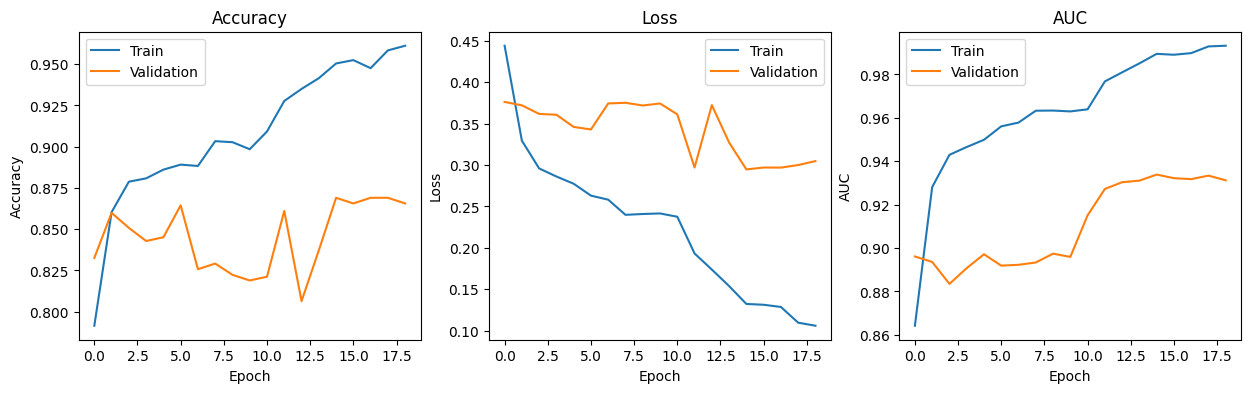

In [31]:
plt.figure(figsize=(15, 4))
for j, (m, title) in enumerate([("accuracy", "Accuracy"), ("loss", "Loss"), ("auc", "AUC")]):
    plt.subplot(1, 3, j + 1)
    plt.plot(hist[m], label="Train")
    plt.plot(hist["val_" + m], label="Validation")
    plt.xlabel("Epoch"); plt.ylabel(title); plt.legend(); plt.title(title)
plt.show()

### 5.1 Umbral de decisión
Con 0.5 el modelo puede ser demasiado conservador y dejar pasar casos patológicos (falsos negativos). El umbral se elige con el **conjunto de validación** (nunca con el de prueba): el que da la **mayor sensibilidad** manteniendo una especificidad mínima (`TARGET_SPECIFICITY`).

In [32]:
val_probs = model.predict(val_ds).ravel()
fpr, tpr, thr = roc_curve(val_labels, val_probs)
spec = 1 - fpr

ok = np.where((spec >= TARGET_SPECIFICITY) & np.isfinite(thr))[0]
best = ok[np.argmax(tpr[ok])] if len(ok) else np.argmax(tpr - fpr)
THRESHOLD = float(thr[best]) if np.isfinite(thr[best]) else 0.5

print(f"AUC en validación: {roc_auc_score(val_labels, val_probs):.4f}")
print(f"Umbral elegido: {THRESHOLD:.3f}")
print(f"En validación con ese umbral -> sensibilidad: {tpr[best]:.3f} | especificidad: {spec[best]:.3f}")

28/28 ━━━━━━━━━━━━━━━━━━━━ 8s 161ms/step
AUC en validación: 0.9340
Umbral elegido: 0.364
En validación con ese umbral -> sensibilidad: 0.848 | especificidad: 0.859


## 6. Model testing
Se evalúa con el 20 % de prueba. En un contexto clínico:
- **Sensibilidad (recall de la clase positiva):** minimiza falsos negativos (casos patológicos no detectados).
- **Especificidad (recall de la clase negativa):** evita tratamientos innecesarios por falsos positivos.

In [33]:
probs = model.predict(test_ds).ravel()
y_true = np.array(test_labels)
print(f"ROC AUC (test): {roc_auc_score(y_true, probs):.4f}\n")

def report(th, title):
    preds = (probs >= th).astype(int)
    cm = confusion_matrix(y_true, preds)
    tn, fp, fn, tp = cm.ravel()
    print("=" * 60)
    print(title)
    print(f"Accuracy: {accuracy_score(y_true, preds):.4f} ({accuracy_score(y_true, preds)*100:.2f}%)\n")
    print(classification_report(y_true, preds, target_names=[NEGATIVE_CLASS, POSITIVE_CLASS], digits=4, zero_division=0))
    print(f"Sensibilidad (recall de '{POSITIVE_CLASS}'): {tp/(tp+fn):.4f}")
    print(f"Especificidad (recall de '{NEGATIVE_CLASS}'): {tn/(tn+fp):.4f}")
    print(f"Falsos negativos: {fn} | Falsos positivos: {fp}\n")
    return cm

cm_default = report(0.5, "Umbral estándar 0.5")
cm = report(THRESHOLD, f"Umbral elegido en validación ({THRESHOLD:.3f})")

46/46 ━━━━━━━━━━━━━━━━━━━━ 4s 93ms/step
ROC AUC (test): 0.9183

Umbral estándar 0.5
Accuracy: 0.8301 (83.01%)

              precision    recall  f1-score   support

     healthy     0.8756    0.8407    0.8578       879
pathological     0.7659    0.8135    0.7890       563

    accuracy                         0.8301      1442
   macro avg     0.8207    0.8271    0.8234      1442
weighted avg     0.8328    0.8301    0.8309      1442

Sensibilidad (recall de 'pathological'): 0.8135
Especificidad (recall de 'healthy'): 0.8407
Falsos negativos: 105 | Falsos positivos: 140

Umbral elegido en validación (0.364)
Accuracy: 0.8024 (80.24%)

              precision    recall  f1-score   support

     healthy     0.8939    0.7668    0.8255       879
pathological     0.7020    0.8579    0.7722       563

    accuracy                         0.8024      1442
   macro avg     0.7980    0.8123    0.7988      1442
weighted avg     0.8190    0.8024    0.8047      1442

Sensibilidad (recall de 'patholo

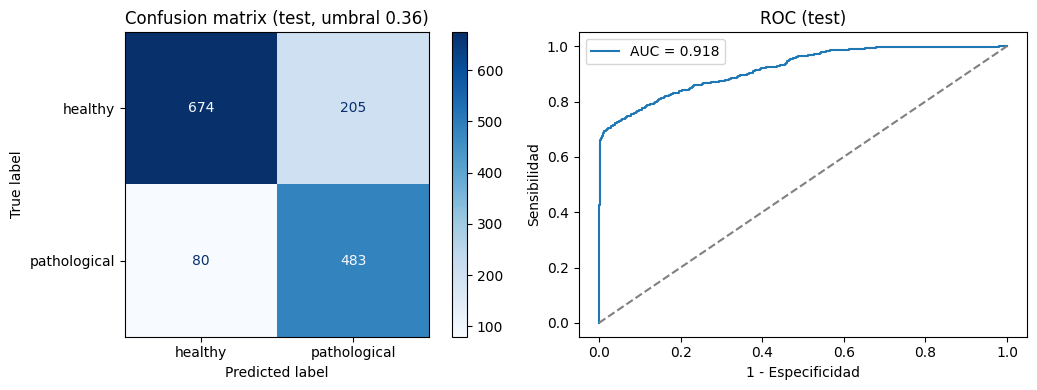

In [34]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(cm, display_labels=[NEGATIVE_CLASS, POSITIVE_CLASS]).plot(cmap="Blues", values_format="d", ax=ax[0])
ax[0].set_title(f"Confusion matrix (test, umbral {THRESHOLD:.2f})")

fpr_t, tpr_t, _ = roc_curve(y_true, probs)
ax[1].plot(fpr_t, tpr_t, label=f"AUC = {roc_auc_score(y_true, probs):.3f}")
ax[1].plot([0, 1], [0, 1], "--", color="gray")
ax[1].set_xlabel("1 - Especificidad"); ax[1].set_ylabel("Sensibilidad"); ax[1].set_title("ROC (test)"); ax[1].legend()
plt.tight_layout(); plt.show()

## 7. Model deployment
### 7.1 Guardar el modelo (.h5)

In [35]:
MODEL_FILE = "breast_cancer_cnn.h5"
model.save(MODEL_FILE)

# Guardar el mapeo de clases junto al modelo
with open("class_mapping.json", "w") as f:
    json.dump({"negative": NEGATIVE_CLASS, "positive": POSITIVE_CLASS, "img_size": IMG_SIZE, "threshold": THRESHOLD}, f)

print("Modelo guardado:", MODEL_FILE, f"({os.path.getsize(MODEL_FILE)/1e6:.1f} MB)")

# Descargar a tu computadora (solo funciona en Colab)
try:
    from google.colab import files
    files.download(MODEL_FILE)
    files.download("class_mapping.json")
except Exception as e:
    print("Descarga manual desde el panel de archivos de Colab.", e)

Modelo guardado: breast_cancer_cnn.h5 (136.4 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 7.2 Inferencia con imágenes nuevas
Sube **al menos 5 imágenes que no formen parte del dataset original** (mismo tipo de imagen que el dataset: mismo estudio/modalidad). Pasan por el mismo preprocesamiento (RGB, 224×224, escala [0,1]).

In [38]:
loaded_model = keras.models.load_model(MODEL_FILE)   # se recarga el modelo guardado

from google.colab import files
uploaded = files.upload()
new_paths = list(uploaded.keys())
if len(new_paths) < 5:
    print("Sube al menos 5 imágenes para cumplir con el requisito.")

Saving N2.jpg to N2.jpg
Saving N3.jpg to N3.jpg
Saving N1-.jpg to N1-.jpg
Saving S2.jpg to S2.jpg
Saving S1.jpg to S1.jpg
Saving S3.jpg to S3.jpg


N2.jpg: Indeterminate (borderline) | Pathology score: 33.4% (threshold 36%)
N3.jpg: No pathology: 97.9% confidence | (pathology score 2.1%)
N1-.jpg: No pathology: 97.1% confidence | (pathology score 2.9%)
S2.jpg: Indeterminate (borderline) | Pathology score: 29.3% (threshold 36%)
S1.jpg: Indeterminate (borderline) | Pathology score: 37.7% (threshold 36%)
S3.jpg: No pathology: 96.4% confidence | (pathology score 3.6%)


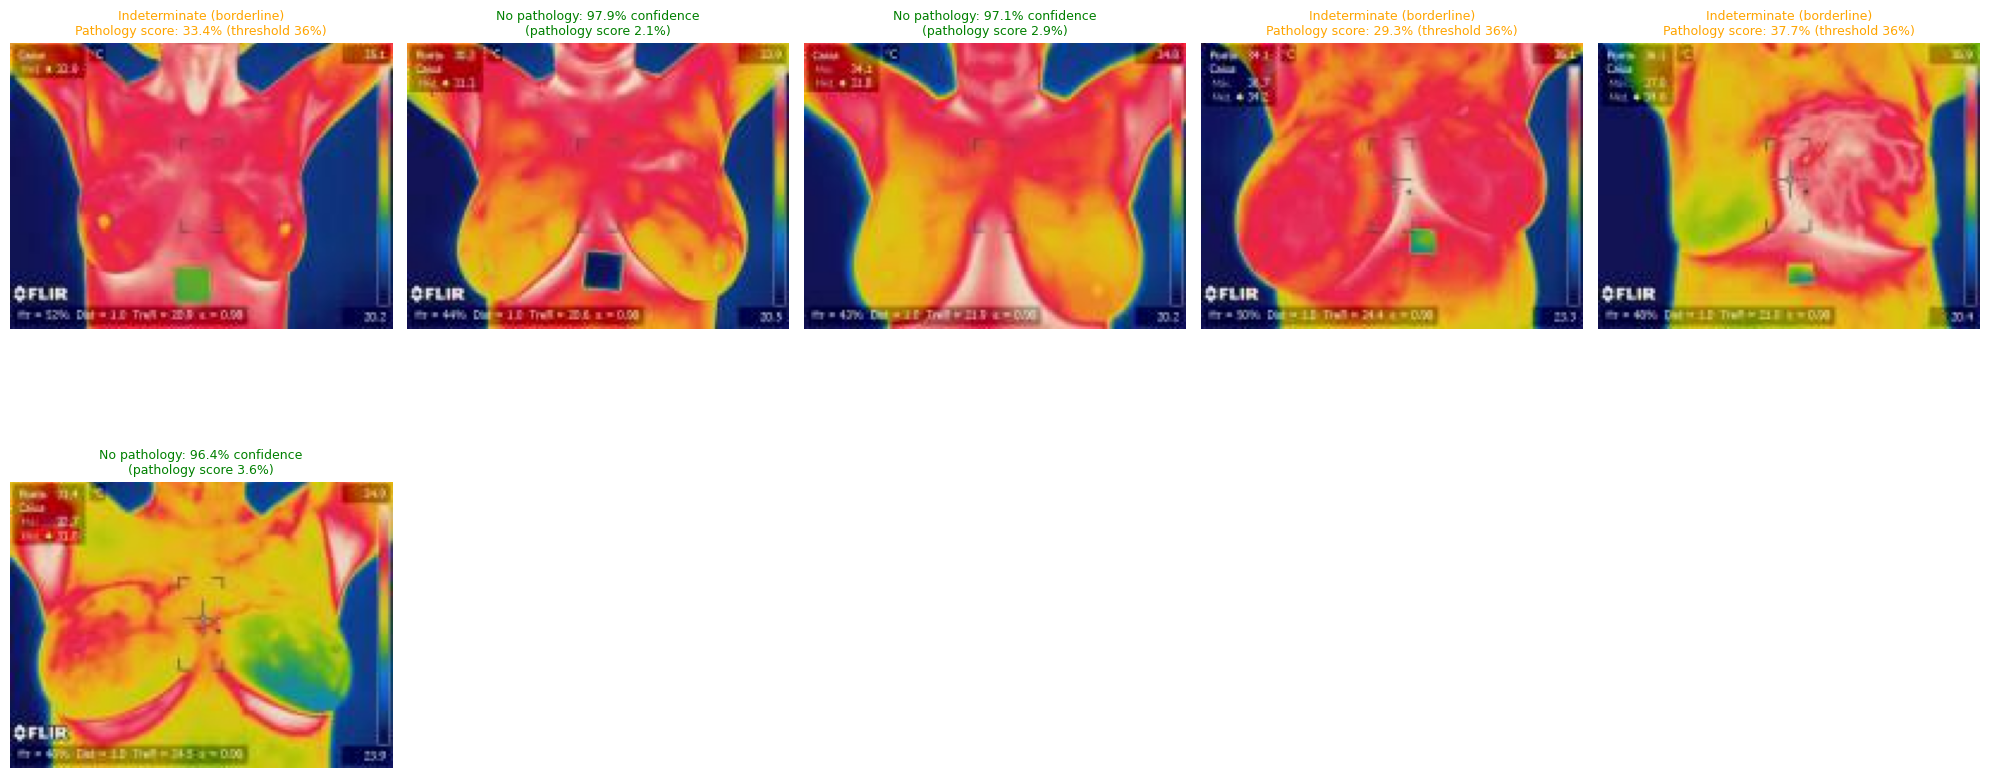

Validación: 9% de imágenes en zona gris | accuracy fuera de ella: 0.877


In [40]:
BAND = 0.10   # zona indeterminada: THRESHOLD ± BAND (definida a priori, no ajustada a estas imágenes)

def classify(prob):
    if abs(prob - THRESHOLD) < BAND:
        return "Indeterminate (borderline)", "orange", None
    if prob >= THRESHOLD:
        return "Pathology Detected", "red", prob          # confianza = score de patología
    return "No pathology", "green", 1 - prob              # confianza = 1 - score

n = len(new_paths); cols = min(n, 5); rows = int(np.ceil(n / cols))
plt.figure(figsize=(4 * cols, 4.8 * rows))

for i, p in enumerate(new_paths):
    img = load_and_preprocess(p)                          # mismo preprocesamiento
    prob = float(loaded_model.predict(img[None, ...], verbose=0)[0][0])
    label, color, conf = classify(prob)
    if conf is None:
        txt = f"{label}\nPathology score: {prob*100:.1f}% (threshold {THRESHOLD*100:.0f}%)"
    else:
        txt = f"{label}: {conf*100:.1f}% confidence\n(pathology score {prob*100:.1f}%)"
    plt.subplot(rows, cols, i + 1)
    plt.imshow(Image.open(p).convert("RGB"))
    plt.title(txt, fontsize=9, color=color); plt.axis("off")
    print(f"{os.path.basename(p)}: {txt.replace(chr(10), ' | ')}")
plt.tight_layout(); plt.show()

# Justificación de la zona gris con VALIDACIÓN (no con las imágenes nuevas)
inb = np.abs(val_probs - THRESHOLD) < BAND
acc_out = ((val_probs >= THRESHOLD) == val_labels)[~inb].mean()
print(f"Validación: {inb.mean()*100:.0f}% de imágenes en zona gris | accuracy fuera de ella: {acc_out:.3f}")